In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

,user_id,number_transactions,total_amount_usd,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,term_deposit,date_joined,device
0,9231c446-cb16-4b2b-a7f7-ddfc8b25aaf6,3.0,2143.0,58,management,married,tertiary,False,True,False,None,261,1,-1,0,None,False,1998-08-23,mobile
1,bb92765a-08de-4963-b432-496524b39157,NaN,NaN,44,technician,single,secondary,False,True,False,None,151,1,-1,0,None,False,2008-07-15,desktop
2,573de577-49ef-42b9-83da-d3cfb817b5c1,2.0,2.0,33,entrepreneur,married,secondary,False,True,True,None,76,1,-1,0,None,False,2002-06-04,mobile
3,d6b66b9d-7c8f-4257-a682-e136f640b7e3,NaN,NaN,47,blue-collar,married,None,False,True,False,None,92,1,-1,0,None,False,1995-06-29,tablet
4,fade0b20-7594-4d9a-84cd-c02f79b1b526,1.0,1.0,33,None,single,None,False,False,False,None,198,1,-1,0,None,False,1995-08-01,mobile


2. Shape of the data:
(45209, 19)

3. Data Types:
user_id                        object
number_transactions           float64
total_amount_usd              float64
age                             int64
job                            object
marital                        object
education                      object
default                          bool
housing                          bool
loan                             bool
contact                        object
duration                        int64
campaign                        int64
pdays                           int64
previous                        int64
poutcome                       object
term_deposit                     bool
date_joined            datetime64[ns]
device                         object
dtype: object

4. Correlations:
                     number_transactions  total_amount_usd       age  \
number_transactions             1.000000         -0.163409 -0.008813   
total_amount_usd               -0.163409          1.

,number_transactions,total_amount_usd,age,duration,campaign,pdays,previous,date_joined
count,35210.000000,35210.000000,45209.000000,45209.000000,45209.000000,45209.000000,45209.000000,45179
mean,3.977052,1369.417751,40.935853,258.153067,2.763897,40.199651,0.580349,1999-06-14 21:54:38.558622336
min,1.000000,-8019.000000,18.000000,0.000000,1.000000,-1.000000,0.000000,1988-01-01 00:00:00
25%,2.000000,73.000000,33.000000,103.000000,1.000000,-1.000000,0.000000,1993-09-18 00:00:00
50%,3.000000,451.000000,39.000000,180.000000,2.000000,-1.000000,0.000000,1999-06-11 00:00:00
75%,4.000000,1438.000000,48.000000,319.000000,3.000000,-1.000000,0.000000,2005-03-18 00:00:00
max,20.000000,102127.000000,95.000000,4918.000000,63.000000,871.000000,275.000000,2010-11-30 00:00:00
std,3.814329,3063.412688,10.618653,257.525446,3.098076,100.130586,2.303489,NaN


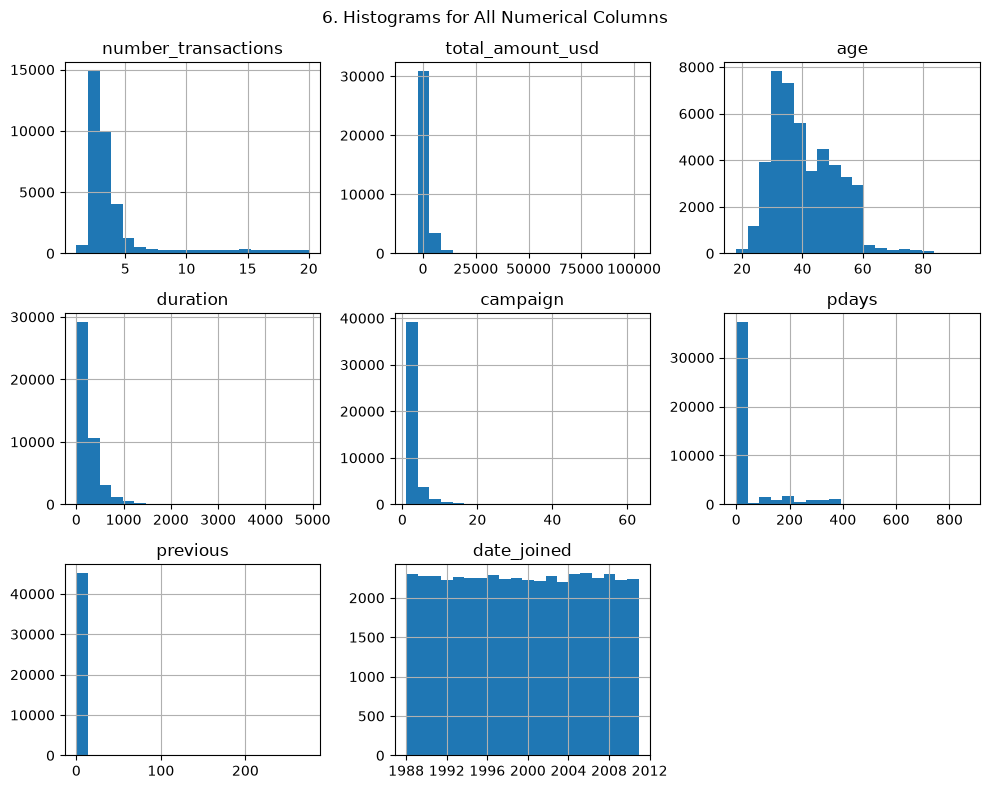

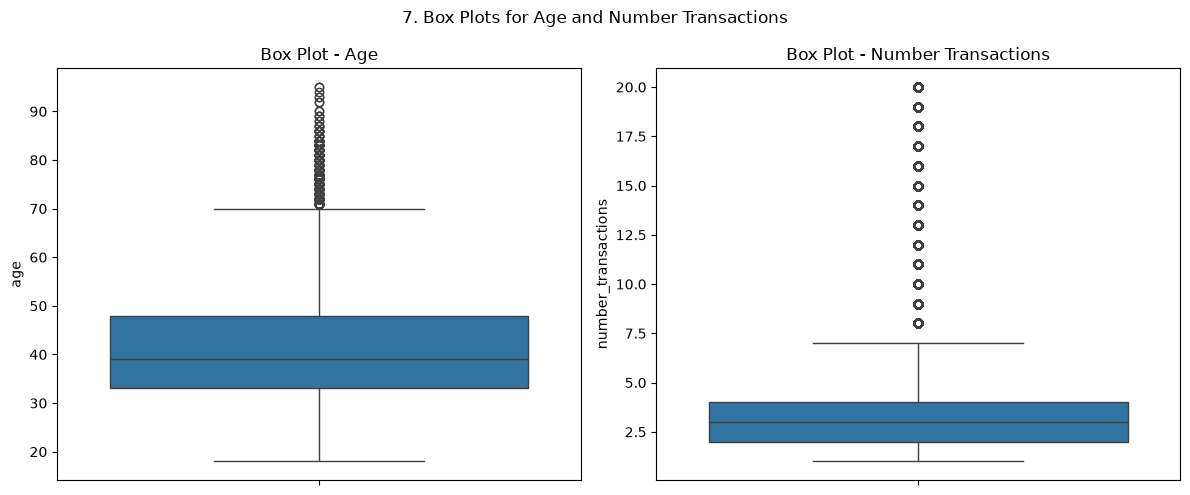

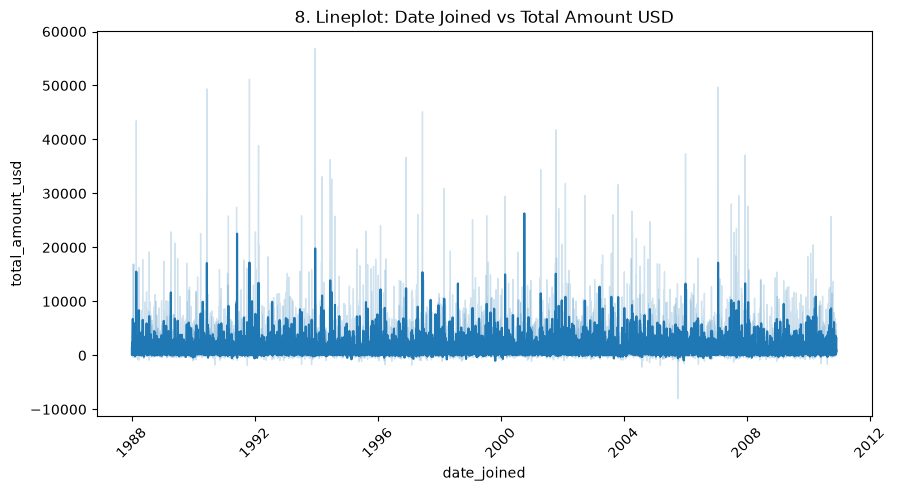

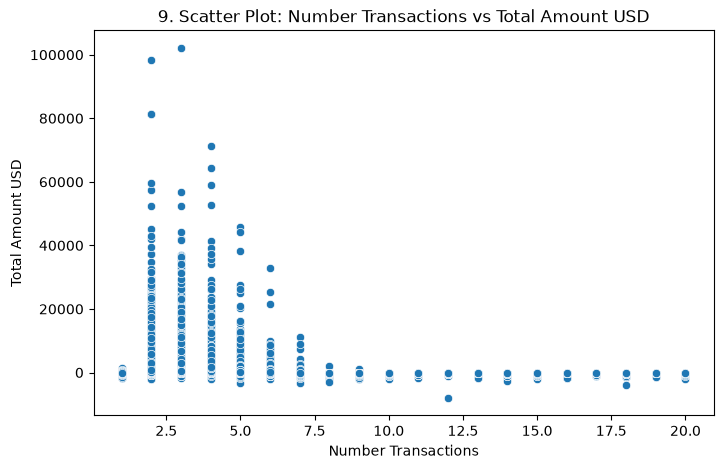

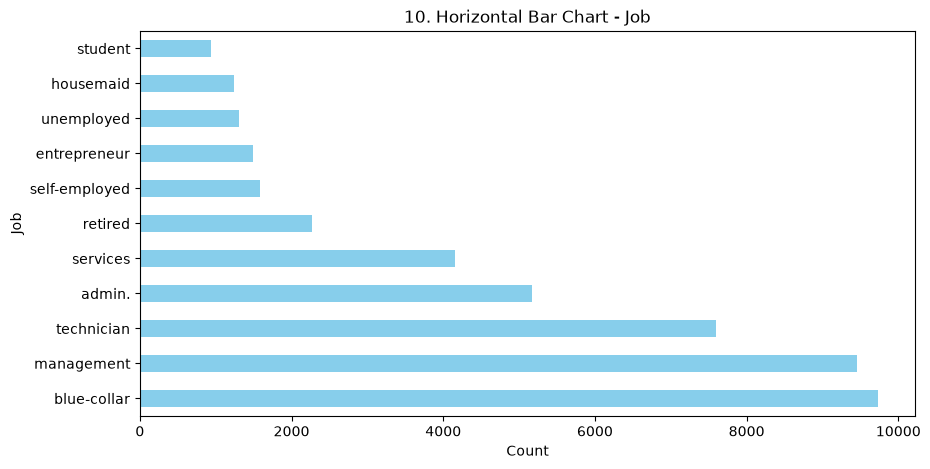

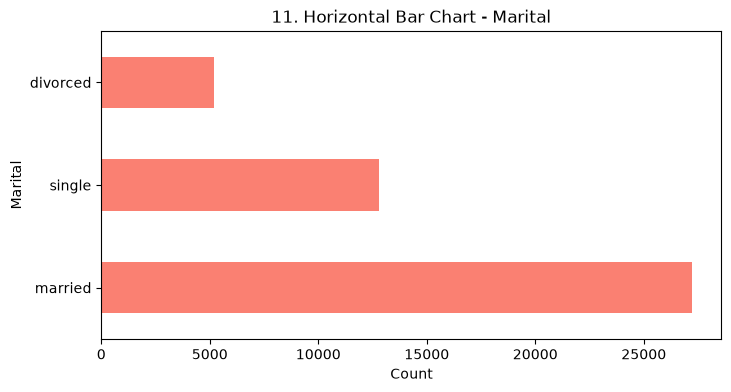

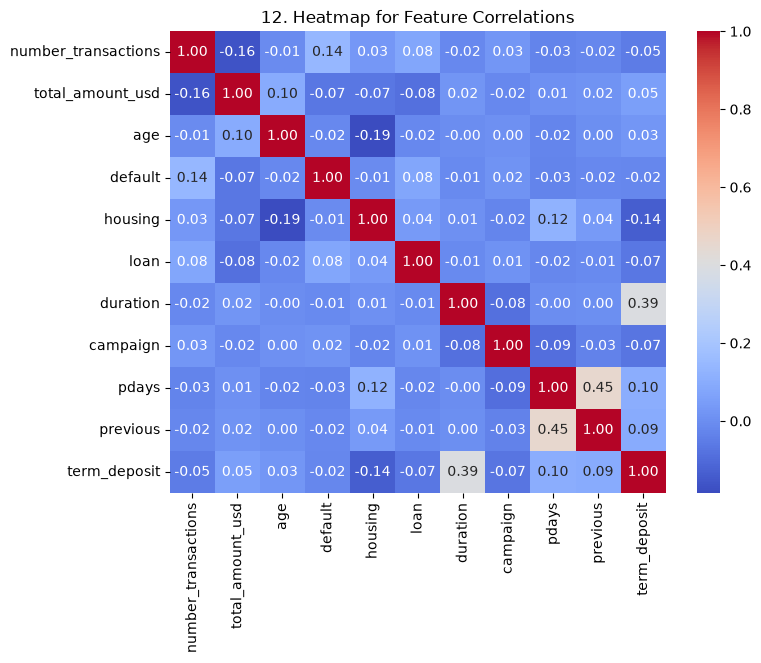


13. Missing Values per Column:
user_id                    0
number_transactions     9999
total_amount_usd        9999
age                        0
job                      288
marital                    0
education               1857
default                    0
housing                    0
loan                       0
contact                13018
duration                   0
campaign                   0
pdays                      0
previous                   0
poutcome               36957
term_deposit               0
date_joined               30
device                    94
dtype: int64


In [ ]:
# 1. Load and preview the data
df = pd.read_pickle("users_data_cleaned.pickle")
display(df.head())

# 2. Check the shape of the data
print("2. Shape of the data:")
print(df.shape)

# 3. Check the data types
print("\n3. Data Types:")
print(df.dtypes)

# 4. Check for correlations
print("\n4. Correlations:")
print(df.corr(numeric_only=True))

# 5. Generate summary statistics for numerical data only
print("\n5. Summary Statistics (Numerical Data Only):")
display(df.describe())

# 6. Plot Histograms for all numerical columns
df.hist(figsize=(10, 8), bins=20)
plt.suptitle("6. Histograms for All Numerical Columns")
plt.tight_layout()
plt.show()

# 7. Generate a box plot for age, dan number_transactions
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(y=df['age'])
plt.title("Box Plot - Age")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['number_transactions'])
plt.title("Box Plot - Number Transactions")
plt.suptitle("7. Box Plots for Age and Number Transactions")
plt.tight_layout()
plt.show()

# 8. Generate a lineplot for date_joined to total_amount_usd
df_sorted = df.sort_values('date_joined')
plt.figure(figsize=(10, 5))
sns.lineplot(data=df_sorted, x='date_joined', y='total_amount_usd')
plt.title("8. Lineplot: Date Joined vs Total Amount USD")
plt.xticks(rotation=45)
plt.show()

# 9. Generate scatter plots comparing total_amount_usd to number_transaction
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='number_transactions', y='total_amount_usd')
plt.title("9. Scatter Plot: Number Transactions vs Total Amount USD")
plt.xlabel("Number Transactions")
plt.ylabel("Total Amount USD")
plt.show()

# 10. Generate Horizontal bar charts for job
plt.figure(figsize=(10, 5))
df['job'].value_counts().plot(kind='barh', color='skyblue')
plt.title("10. Horizontal Bar Chart - Job")
plt.xlabel("Count")
plt.ylabel("Job")
plt.show()

# 11. Generate Horizontal bar charts for marital
plt.figure(figsize=(8, 4))
df['marital'].value_counts().plot(kind='barh', color='salmon')
plt.title("11. Horizontal Bar Chart - Marital")
plt.xlabel("Count")
plt.ylabel("Marital")
plt.show()

# 12. Generate a heatmap for feature/future correlations
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("12. Heatmap for Feature Correlations")
plt.show()

# 13. Identify Missing Values
print("\n13. Missing Values per Column:")
print(df.isnull().sum())

In [16]:
## Soal 2 
Diberikan dataset Sales_Data.csv yang berisikan informasi berupa Biaya Promo dan Nilai Penjualan. Buatlah sebuah code untuk memprediksi biaya promosi yang berhubungan dengan nilai penjualan. Gunakanlah algoritma LinearRegression untuk prediksi. Komponen penilaian: 

SyntaxError: invalid syntax (2133814625.py, line 2)

=== 1.b. Variabel dalam Dataset ===
['BiayaPromo', 'NilaiPenjualan']


,BiayaPromo,NilaiPenjualan
0,1500,90500
1,1800,89500
2,1900,105000
3,2050,102000
4,2050,90500



=== 1.c. Data Split (80% Train, 20% Test) ===
Jumlah data Training: 16 baris
Jumlah data Testing: 4 baris

=== 1.d. Model LinearRegression Berhasil Dilatih ===

=== 1.e. Hasil Prediksi dari Data Test ===
Aktual: 90500 | Prediksi: 79244.65
Aktual: 170500 | Prediksi: 199104.61
Aktual: 194500 | Prediksi: 194310.21
Aktual: 89500 | Prediksi: 93627.85


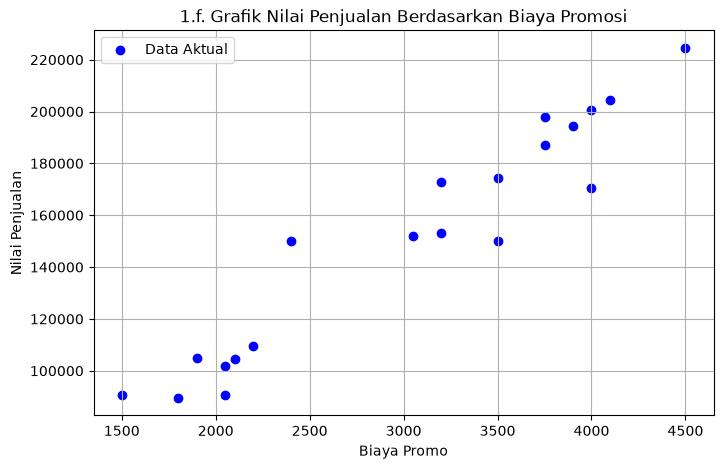

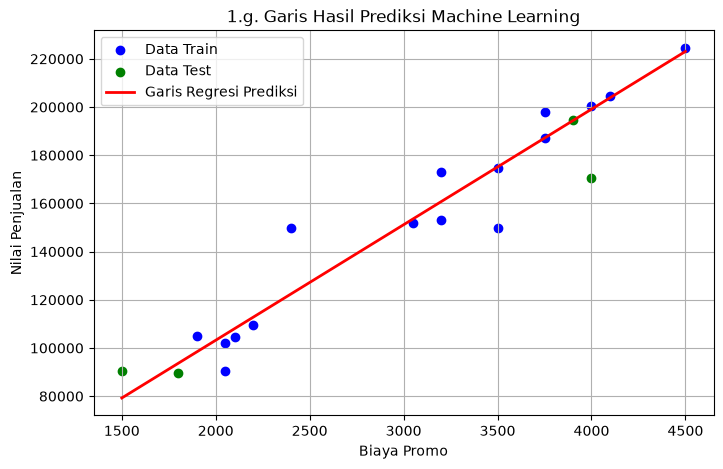


=== 2. Hasil Perhitungan Komponen Statistik ===
a. Intercept : 7328.681859251141
b. Slope     : 47.94398152795902
c. R-Square  : 0.9190200703772093


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 1.a. Membaca file Sales_Data.csv dengan pemisah titik koma (sep=';')
df_sales = pd.read_csv("Sales_Data.csv", sep=';')

# 1.b. Menampilkan variabel dalam dataset
print("=== 1.b. Variabel dalam Dataset ===")
print(df_sales.columns.tolist())
display(df_sales.head())

# Menentukan Variabel Independen (X) dan Dependen (y)
X = df_sales[['BiayaPromo']] 
y = df_sales['NilaiPenjualan']

# 1.c. Menampilkan data yang di-split (train: 80% & test: 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("\n=== 1.c. Data Split (80% Train, 20% Test) ===")
print(f"Jumlah data Training: {X_train.shape[0]} baris")
print(f"Jumlah data Testing: {X_test.shape[0]} baris")

# 1.d. Memanggil LinearRegression() dan melakukan training
model = LinearRegression()
model.fit(X_train, y_train)
print("\n=== 1.d. Model LinearRegression Berhasil Dilatih ===")

# 1.e. Menampilkan hasil predict dari data test
y_pred = model.predict(X_test)
print("\n=== 1.e. Hasil Prediksi dari Data Test ===")
for actual, predicted in zip(y_test, y_pred):
    print(f"Aktual: {actual} | Prediksi: {predicted:.2f}")

# 1.f. Menampilkan Grafik Nilai Penjualan berdasarkan Biaya Promosi
plt.figure(figsize=(8, 5))
plt.scatter(df_sales['BiayaPromo'], df_sales['NilaiPenjualan'], color='blue', label='Data Aktual')
plt.xlabel("Biaya Promo")
plt.ylabel("Nilai Penjualan")
plt.title("1.f. Grafik Nilai Penjualan Berdasarkan Biaya Promosi")
plt.legend()
plt.grid(True)
plt.show()

# 1.g. Menampilkan Garis hasil prediksi pada Biaya Promosi terhadap penjualan (train set & test set)
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color='blue', label='Data Train')
plt.scatter(X_test, y_test, color='green', label='Data Test')
plt.plot(X, model.predict(X), color='red', linewidth=2, label='Garis Regresi Prediksi')
plt.xlabel("Biaya Promo")
plt.ylabel("Nilai Penjualan")
plt.title("1.g. Garis Hasil Prediksi Machine Learning")
plt.legend()
plt.grid(True)
plt.show()

# 2. Perhitungan Komponen Statistik Model
print("\n=== 2. Hasil Perhitungan Komponen Statistik ===")
print(f"a. Intercept : {model.intercept_}")
print(f"b. Slope     : {model.coef_[0]}")
print(f"c. R-Square  : {model.score(X, y)}")

## Soal Nim 1,3

=== 2. Sebanyak 8 Row Data Teratas ===


,preg,glukosa,pres,skin,insulin,BMI,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0



=== 3. Data Features dan Label (9 Row Teratas) ===


,preg,glukosa,pres,skin,insulin,BMI,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1



=== 4. Data Split (85% Train & 15% Test) ===
Jumlah data Training: 652 baris
Jumlah data Testing: 116 baris

=== 5. Model KNeighborsClassifier Berhasil Dilatih (k=5, Euclidean) ===

=== 6. Score Akurasi Model (k=5) ===
Akurasi: 0.6724


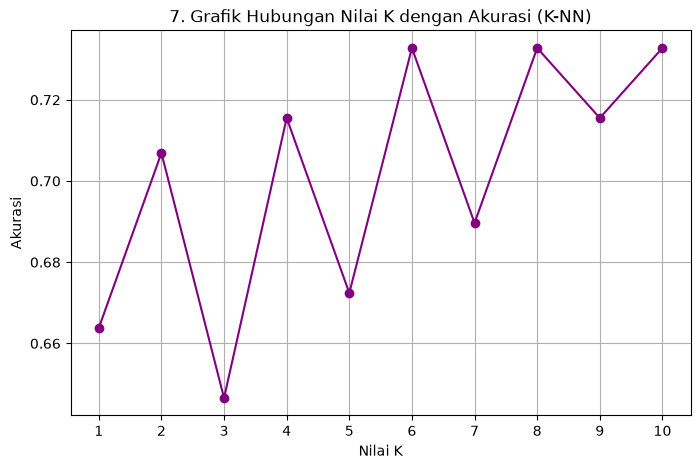

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Membaca file pima-indians-diabetes.data.csv (tanpa header=None karena sudah ada header di file)
df_pima = pd.read_csv("pima-indians-diabetes.data.csv")

# 2. Menampilkan sebanyak 8 row data teratas
print("=== 2. Sebanyak 8 Row Data Teratas ===")
display(df_pima.head(8))

# 3. Menampilkan data features dan label sebanyak 9 row teratas
X_pima = df_pima.iloc[:, :-1]
y_pima = df_pima.iloc[:, -1]
print("\n=== 3. Data Features dan Label (9 Row Teratas) ===")
display(pd.concat([X_pima, y_pima], axis=1).head(9))

# 4. Menampilkan data yang di-split (train: 85% & test: 15%)
X_train, X_test, y_train, y_test = train_test_split(X_pima, y_pima, test_size=0.15, random_state=42)
print("\n=== 4. Data Split (85% Train & 15% Test) ===")
print(f"Jumlah data Training: {X_train.shape[0]} baris")
print(f"Jumlah data Testing: {X_test.shape[0]} baris")

# 5. Memanggil KNeighborsClassifier dengan n_neighbors=5, Euclidean distance
knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn.fit(X_train, y_train)
print("\n=== 5. Model KNeighborsClassifier Berhasil Dilatih (k=5, Euclidean) ===")

# 6. Hitunglah score akurasinya
y_pred = knn.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"\n=== 6. Score Akurasi Model (k=5) ===")
print(f"Akurasi: {accuracy:.4f}")

# 7. Buat grafik menampilkan k yang berhubungan dengan nilai akurasinya (maks k = 10)
k_values = range(1, 11)
accuracies = []

for k in k_values:
    clf = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    accuracies.append(accuracy_score(y_test, preds))

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', color='purple', linestyle='-')
plt.title("7. Grafik Hubungan Nilai K dengan Akurasi (K-NN)")
plt.xlabel("Nilai K")
plt.ylabel("Akurasi")
plt.xticks(k_values)
plt.grid(True)
plt.show()

## Soal 2,4

=== 2. Sebanyak 7 Row Data Teratas ===


,No,Gaji,Pengeluaran
0,1,2500,1750
1,2,3800,4200
2,3,3900,3800
3,4,4350,5500
4,5,4400,3200
5,6,5500,5450
6,7,5600,5950



=== 4. Sebanyak 9 Row Data Teratas (Tanpa Kolom No) ===


,Gaji,Pengeluaran
0,2500,1750
1,3800,4200
2,3900,3800
3,4350,5500
4,4400,3200
5,5500,5450
6,5600,5950
7,5750,4100
8,6850,6050


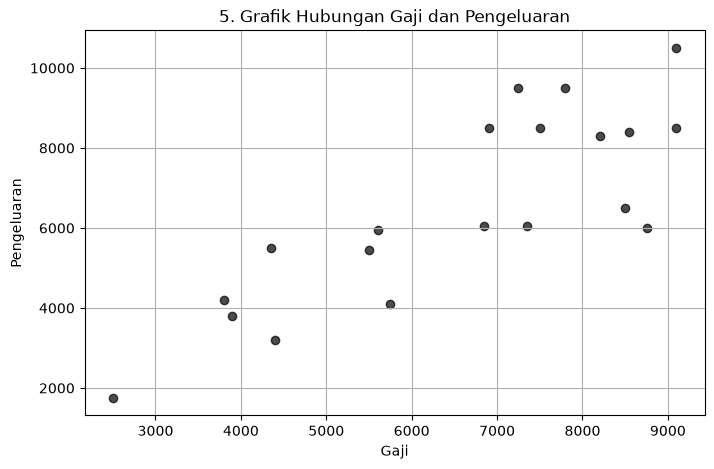


=== 7. Nilai Pusat Klaster (Centroids) ===
[[4475.   4243.75]
 [7987.5  8025.  ]]


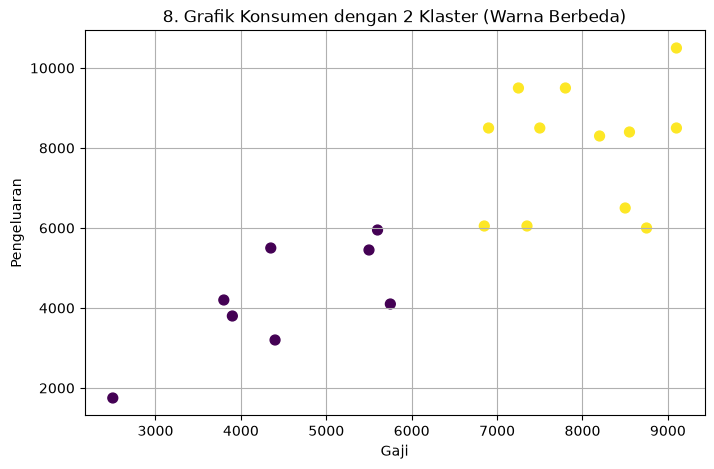

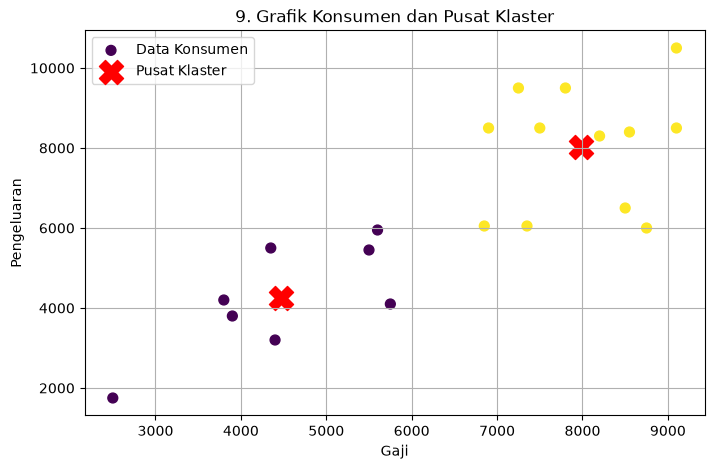

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Membaca file konsumen.csv dengan pemisah titik koma (sep=';')
df_konsumen = pd.read_csv("konsumen.csv", sep=';')

# 2. Menampilkan sebanyak 7 row data teratas
print("=== 2. Sebanyak 7 Row Data Teratas ===")
display(df_konsumen.head(7))

# 3. Menghapus kolom No (menggunakan indeks kolom ke-0 agar aman dari error penulisan nama)
df_konsumen = df_konsumen.drop(df_konsumen.columns[0], axis=1)

# 4. Menampilkan 9 row data teratas (setelah kolom No dihapus)
print("\n=== 4. Sebanyak 9 Row Data Teratas (Tanpa Kolom No) ===")
display(df_konsumen.head(9))

# 5. Menampilkan grafik hubungan gaji dan pengeluaran
plt.figure(figsize=(8, 5))
plt.scatter(df_konsumen['Gaji'], df_konsumen['Pengeluaran'], color='black', alpha=0.7)
plt.title("5. Grafik Hubungan Gaji dan Pengeluaran")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.grid(True)
plt.show()

# 6. Gunakan 2 klaster
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df_konsumen['Cluster'] = kmeans.fit_predict(df_konsumen[['Gaji', 'Pengeluaran']])

# 7. Menampilkan nilai pusat klaster
print("\n=== 7. Nilai Pusat Klaster (Centroids) ===")
print(kmeans.cluster_centers_)

# 8. Menampilkan Grafik Konsumen yang memiliki 2 warna berbeda
plt.figure(figsize=(8, 5))
plt.scatter(df_konsumen['Gaji'], df_konsumen['Pengeluaran'], c=df_konsumen['Cluster'], cmap='viridis', s=50)
plt.title("8. Grafik Konsumen dengan 2 Klaster (Warna Berbeda)")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.grid(True)
plt.show()

# 9. Menampilkan Grafik Konsumen yang memiliki 2 warna berbeda dengan pusat klaster
plt.figure(figsize=(8, 5))
plt.scatter(df_konsumen['Gaji'], df_konsumen['Pengeluaran'], c=df_konsumen['Cluster'], cmap='viridis', s=50, label='Data Konsumen')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=300, c='red', marker='X', label='Pusat Klaster')
plt.title("9. Grafik Konsumen dan Pusat Klaster")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.legend()
plt.grid(True)
plt.show()